# Week 8 — Fabric-Wise and Defect-Wise Analysis
Where does each method work and where does it fail? Results are broken down by fabric, by defect type and by defect size, with bootstrap intervals (resampling source images) and counts for every group, followed by a study of the failure cases. Two controls are added so that conclusions about the adaptive pipeline are not confounded: a fixed multi-scale pipeline with per-fabric references and thresholds, and an LBP variant that compares each window with its own patch.

**SETUP**  
Imports and every tunable parameter. QUICK = True runs a small smoke test. The evaluation splits and calibration data are identical to the main evaluation (same seed and same order of random draws).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import random
from numpy.lib.stride_tricks import sliding_window_view
from scipy import ndimage
from scipy.signal import windows, fftconvolve
from scipy.stats import gumbel_r, spearmanr
from sklearn.metrics import average_precision_score, roc_auc_score
from skimage.feature import local_binary_pattern
try:
    from skimage.feature import graycomatrix, graycoprops
except ImportError:
    from skimage.feature import greycomatrix as graycomatrix, greycoprops as graycoprops

QUICK = True          # True: small smoke test
EVAL_SPLIT = "dev"       # keep "dev"; the test split is reserved for the final comparison

SEED = 42
rng = np.random.default_rng(SEED)      # same draws, in the same order, as the main evaluation
random.seed(SEED)

SCALES_ALL = [32, 64, 128, 256]

METHODS = ["LBP", "LBP self-reference", "GLCM", "Gabor",
           "FFT fixed single-scale", "FFT fixed multi-scale",
           "FFT fixed multi-scale (per-fabric)", "FFT adaptive multi-scale"]   # delete names to run fewer methods
FOCUS_METHODS = ["FFT adaptive multi-scale", "FFT fixed multi-scale (per-fabric)", "Gabor"]

CFG = dict(
    detrend=True, peak_k=6.0, dilate_r=2, lowcut=1.5, notch_depth=0.0,
    fixed_single_scales=[128], fixed_multi_scales=[64, 128, 256], fixed_sigma=4.0,
    c_periods=4, n_adapt_scales=3, sigma_periods=1.0,
    win=32, step=16, lbp_radii=[1, 2, 3], gray_levels=8, gabor_ksize=15,
    self_win=16, self_step=8,          # window used by the LBP self-reference variant
    target_fpr=0.05, thr_estimator="gumbel",
    r_open=1, r_close=3, min_area=16,
    low_frac_grid=[1.0, 0.9, 0.8, 0.7, 0.6, 0.5],
    max_ref=150, max_cal=60, max_ntest=40, var_threshold=5.0, border_margin=16,
    n_boot=200, min_sources=5,         # groups with fewer source images are marked as low-n
    edge_px=24, low_contrast=0.5, near_miss=0.7,   # failure-analysis rules
)
if QUICK:
    CFG.update(max_ref=30, max_cal=15, max_ntest=10, n_boot=50, min_sources=3)
METHODS = [m for m in METHODS]
FOCUS_METHODS = [m for m in FOCUS_METHODS if m in METHODS]

Mounted at /content/drive


**LOAD DATASET**  
Patch folders, a results folder, and the defect-code names from the dataset description.

In [2]:
PATCHED_DIR = Path("/content/drive/MyDrive/ECE501/processed_patches")
PATCH_IMAGE_DIR = PATCHED_DIR / "images"
PATCH_MASK_DIR = PATCHED_DIR / "masks"
NODEFECT_PATCH_DIR = PATCHED_DIR / "nodefect_images"

RESULTS_DIR = Path("/content/drive/MyDrive/ECE501/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DEFECT_CODES = {2: "Broken end", 6: "Broken yarn", 10: "Broken pick", 16: "Weft curling", 19: "Fuzzyball",
                22: "Cut selvage", 23: "Crease", 25: "Warp ball", 27: "Knots", 29: "Contamination",
                30: "Nep", 36: "Weft crack"}

defect_patch_files = sorted(PATCH_IMAGE_DIR.glob("*.png"))
nodefect_patch_files = sorted(NODEFECT_PATCH_DIR.glob("*.png"))

print("=" * 60)
print("DATASET LOADED")
print("=" * 60)
print(f"Patches from defective images : {len(defect_patch_files)}")
print(f"Defect-free patches           : {len(nodefect_patch_files)}")
print(f"Mode                          : {'QUICK (smoke test)' if QUICK else 'FULL'} | evaluation split: {EVAL_SPLIT}")

DATASET LOADED
Patches from defective images : 3222
Defect-free patches           : 4371
Mode                          : FULL | evaluation split: dev


**HELPERS, TABLES AND LEAK-FREE SPLITS**  
Fabric code = third filename token, defect code = second, source image = first three. Defect patches are split into DEV / TEST by source image; defect-free patches per fabric into REF / CAL / NTEST by source image.

In [3]:
def get_fabric_type(stem):
    parts = stem.split("_")
    return parts[2] if len(parts) >= 3 else "unknown"

def get_defect_name(stem):
    parts = stem.split("_")
    try:
        code = int(parts[1])
    except (IndexError, ValueError):
        return "unknown"
    return DEFECT_CODES.get(code, f"code {code}")

def get_source_id(stem):
    return "_".join(stem.split("_")[:3])

def load_gray(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    return None if img is None else img.astype(np.float32)

rows = []
for f in defect_patch_files:
    m = cv2.imread(str(PATCH_MASK_DIR / f.name), cv2.IMREAD_GRAYSCALE)
    if m is not None and np.count_nonzero(m) > 0:
        rows.append(dict(file=f, source=get_source_id(f.stem), fabric=get_fabric_type(f.stem), defect_type=get_defect_name(f.stem)))
defect_df = pd.DataFrame(rows)
nodefect_df = pd.DataFrame([dict(file=f, source=get_source_id(f.stem), fabric=get_fabric_type(f.stem))
                            for f in nodefect_patch_files])

FABRICS = sorted(set(defect_df.fabric) & set(nodefect_df.fabric))
nodefect_df = nodefect_df[nodefect_df.fabric.isin(FABRICS)].copy()

src = sorted(defect_df.source.unique())
perm = list(rng.permutation(src))
dev_src = set(perm[: len(perm) // 2])
defect_df["split"] = np.where(defect_df.source.isin(dev_src), "dev", "test")

role = {}
for fab in FABRICS:
    ids = sorted(nodefect_df[nodefect_df.fabric == fab].source.unique())
    perm = list(rng.permutation(ids))
    n = len(perm)
    n_ref = max(1, int(round(0.5 * n)))
    n_cal = max(1, int(round(0.25 * n)))
    for s in perm[:n_ref]:
        role[s] = "ref"
    for s in perm[n_ref:n_ref + n_cal]:
        role[s] = "cal"
    for s in perm[n_ref + n_cal:]:
        role[s] = "ntest"
nodefect_df["role"] = nodefect_df.source.map(role)

print("=" * 60)
print("SPLIT SUMMARY")
print("=" * 60)
print(f"Fabrics: {FABRICS}")
print("Defect patches by split:")
print(defect_df.groupby(["fabric", "split"]).size().unstack(fill_value=0).to_string())
print("\nDefect patches by defect type and split:")
print(defect_df.groupby(["defect_type", "split"]).size().unstack(fill_value=0).to_string())

SPLIT SUMMARY
Fabrics: ['00', '01', '02', '03', '04', '05', '06']
Defect patches by split:
split   dev  test
fabric           
00       11     6
01       12    41
02       41    40
03       91    85
04       14    10
05        0     2
06        8     6

Defect patches by defect type and split:
split          dev  test
defect_type             
Broken end      10     9
Broken pick     73    54
Broken yarn      5    16
Contamination    3     0
Crease           2     9
Cut selvage     10    13
Fuzzyball       45    36
Knots            0     2
Nep             21     8
Warp ball        4     6
Weft crack       0    29
Weft curling     4     8


**FOURIER SPECTRAL-RESIDUAL TOOLKIT**  
Windowed FFT (mean and linear brightness ramp removed per window), peak detection in the log-spectrum, the notch mask, and the residual-energy map.

In [4]:
HANN = {W: np.outer(windows.hann(W, sym=False), windows.hann(W, sym=False)).astype(np.float32)
        for W in SCALES_ALL}
_PLANE = {}

def detrend_windows(wins, W):
    if W not in _PLANE:
        y, x = np.mgrid[0:W, 0:W]
        A = np.stack([np.ones(W * W), (x.ravel() - (W - 1) / 2) / W, (y.ravel() - (W - 1) / 2) / W], axis=1)
        _PLANE[W] = (A, np.linalg.pinv(A))
    A, P = _PLANE[W]
    flat = wins.reshape(len(wins), -1).astype(np.float64)
    return (flat - (flat @ P.T) @ A.T).reshape(len(wins), W, W).astype(np.float32)

def windowed_fft(wins, W):
    wins = detrend_windows(wins, W) if CFG["detrend"] else wins - wins.mean(axis=(1, 2), keepdims=True)
    return np.fft.fft2(wins * HANN[W])

def tile_windows(img, W):
    return sliding_window_view(img, (W, W))[::W, ::W].reshape(-1, W, W)

def padded_windows(img, W):
    pad, stride = W // 2, W // 2
    p = np.pad(img, pad, mode="reflect")
    v = sliding_window_view(p, (W, W))[::stride, ::stride]
    return v.reshape(-1, W, W), v.shape[0], v.shape[1], p.shape, pad, stride

def freq_radius(W):
    k = np.fft.fftfreq(W) * W
    return np.hypot(k[:, None], k[None, :])

def peak_zscore(mag, W):
    L = np.log1p(mag)
    bg = ndimage.median_filter(L, size=max(5, (W // 16) | 1), mode="wrap")
    d = L - bg
    return d / (np.median(np.abs(d - np.median(d))) * 1.4826 + 1e-8)

def make_notch(mag, W, cfg):
    notch = (peak_zscore(mag, W) > cfg["peak_k"]) | (freq_radius(W) <= cfg["lowcut"])
    r = cfg["dilate_r"]
    if r > 0:
        yy, xx = np.ogrid[-r:r + 1, -r:r + 1]
        notch = ndimage.maximum_filter(notch.astype(np.uint8), footprint=(yy ** 2 + xx ** 2) <= r ** 2, mode="wrap") > 0
    return notch

def top_periods(mag, W, n=3, min_rad=3, excl=3):
    z = peak_zscore(mag, W).copy()
    z[freq_radius(W) <= min_rad] = -np.inf
    k = np.fft.fftfreq(W) * W
    out = []
    for _ in range(n):
        iy, ix = np.unravel_index(np.argmax(z), z.shape)
        out.append((float(W / np.hypot(k[iy], k[ix])), float(z[iy, ix])))
        for cy, cx in ((iy, ix), ((-iy) % W, (-ix) % W)):
            z[np.ix_(np.arange(cy - excl, cy + excl + 1) % W, np.arange(cx - excl, cx + excl + 1) % W)] = -np.inf
    return out

_H2_CACHE = {}

def hann_overlap(W, pshape):
    key = (W, pshape)
    if key not in _H2_CACHE:
        acc = np.zeros(pshape, dtype=np.float32)
        h2 = HANN[W] ** 2
        for y in range(0, pshape[0] - W + 1, W // 2):
            for x in range(0, pshape[1] - W + 1, W // 2):
                acc[y:y + W, x:x + W] += h2
        _H2_CACHE[key] = np.maximum(acc, 1e-3)
    return _H2_CACHE[key]

def residual_log_energy(img, W, notch, sigma, depth=0.0):
    wins, ny, nx, pshape, pad, stride = padded_windows(img, W)
    F = np.where(notch, windowed_fft(wins, W) * depth, windowed_fft(wins, W))
    r = np.fft.ifft2(F).real.astype(np.float32)
    acc = np.zeros(pshape, dtype=np.float32)
    k = 0
    for iy in range(ny):
        for ix in range(nx):
            acc[iy * stride:iy * stride + W, ix * stride:ix * stride + W] += r[k] ** 2
            k += 1
    E = (acc / hann_overlap(W, pshape))[pad:-pad, pad:-pad]
    if sigma > 0:
        E = ndimage.gaussian_filter(E, sigma, mode="reflect")
    return np.log(E + 1e-3)

**REFERENCE SPECTRA, PERIODICITY AND ADAPTIVE RULES**  
Mean windowed spectrum of the REF defect-free patches per fabric. The strongest peak gives each fabric's weave period, which sets the adaptive window sizes. Periodicity strength (peak prominence and the share of spectral energy in the notch) is kept for the analysis of detection versus weave pattern.

In [6]:
def sample_files(files, cap, rng):
    files = list(files)
    if len(files) > cap:
        idx = rng.choice(len(files), size=cap, replace=False)
        files = [files[i] for i in sorted(idx)]
    return files

ref_files = {}
for fab in FABRICS:
    sub = nodefect_df[(nodefect_df.fabric == fab) & (nodefect_df.role == "ref")]
    ref_files[fab] = sample_files(sub.file.tolist(), CFG["max_ref"], rng)

ref_sums = {f: {W: np.zeros((W, W)) for W in SCALES_ALL} for f in FABRICS}
ref_cnt = {f: {W: 0 for W in SCALES_ALL} for f in FABRICS}
for fab in FABRICS:
    for f in ref_files[fab]:
        img = load_gray(f)
        if img is None:
            continue
        for W in SCALES_ALL:
            tiles = tile_windows(img, W)
            keep = tiles.std(axis=(1, 2)) >= CFG["var_threshold"]
            if keep.any():
                ref_sums[fab][W] += np.abs(windowed_fft(tiles[keep], W)).sum(axis=0)
                ref_cnt[fab][W] += int(keep.sum())

mags = {f: {W: ref_sums[f][W] / max(ref_cnt[f][W], 1) for W in SCALES_ALL} for f in FABRICS}
pooled_mags = {W: sum(ref_sums[f][W] for f in FABRICS) / max(sum(ref_cnt[f][W] for f in FABRICS), 1) for W in SCALES_ALL}

def adaptive_params(P, cfg):
    cand = [W for W in SCALES_ALL if W >= cfg["c_periods"] * P] or [SCALES_ALL[-1]]
    start = SCALES_ALL.index(cand[0])
    return SCALES_ALL[start:start + cfg["n_adapt_scales"]], float(np.clip(P * cfg["sigma_periods"], 2, 12))

cfg_nolow = {**CFG, "lowcut": 0}
adapt_params, feas = {}, []
for fab in FABRICS:
    peaks = top_periods(mags[fab][256], 256, n=3)
    scales, sigma = adaptive_params(peaks[0][0], CFG)
    adapt_params[fab] = dict(P=peaks[0][0], scales=scales, sigma=sigma)
    mag = mags[fab][256].copy(); mag[0, 0] = 0
    energy = float((mag ** 2)[make_notch(mags[fab][256], 256, cfg_nolow)].sum() / (mag ** 2).sum())
    feas.append(dict(fabric=fab, main_period_px=round(peaks[0][0], 1), peak_strength_z=round(peaks[0][1], 1),
                     notch_energy_pct=round(100 * energy, 1), adaptive_scales=str(scales), sigma=round(sigma, 1)))
fab_feas_df = pd.DataFrame(feas).set_index("fabric")

print("=" * 60)
print("PERIODICITY AND ADAPTIVE PARAMETERS")
print("=" * 60)
print(fab_feas_df.to_string())

PERIODICITY AND ADAPTIVE PARAMETERS
        main_period_px  peak_strength_z  notch_energy_pct adaptive_scales  sigma
fabric                                                                          
00                 5.7             63.3              84.7   [32, 64, 128]    5.7
01                 5.1             62.9              76.4   [32, 64, 128]    5.1
02                 4.2             71.4              84.1   [32, 64, 128]    4.2
03                 5.9             69.8              94.7   [32, 64, 128]    5.9
04                 5.4             68.0              61.8   [32, 64, 128]    5.4
05                 4.2             58.1              60.1   [32, 64, 128]    4.2
06                 5.6             68.1              71.1   [32, 64, 128]    5.6


**BASELINE DESCRIPTORS**  
Same protocol as the Fourier method: per-fabric reference from REF patches, robust normalisation and a calibrated threshold from CAL patches. LBP (multi-radius uniform histograms, chi-square distance), GLCM and Gabor (z-score distance) use 32x32 windows with stride 16. The LBP self-reference variant uses 16x16 windows (stride 8) and compares each window with the median window of its own patch, so it needs no external reference.

In [7]:
ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
PROPS = ["contrast", "energy", "homogeneity", "correlation"]
_GRIDS = {}

def grid_for(win, step):
    key = (win, step)
    if key not in _GRIDS:
        pos = list(range(0, 256 - win + 1, step)); tpos = list(range(0, 256 - win + 1, win))
        cnt = np.zeros((256, 256), np.float32)
        for y in pos:
            for x in pos:
                cnt[y:y + win, x:x + win] += 1
        _GRIDS[key] = (pos, tpos, cnt)
    return _GRIDS[key]

def build_gabor_bank():
    ks = []
    for theta in ANGLES:
        for freq in (0.1, 0.25, 0.4):
            ks.append(cv2.getGaborKernel((CFG["gabor_ksize"],) * 2, 4.0, theta, 1.0 / freq, 0.5, 0, ktype=cv2.CV_32F))
    return ks

GABOR_KERNELS = build_gabor_bank()
_GABOR_STACK = np.stack([k[::-1, ::-1] for k in GABOR_KERNELS]).astype(np.float32)

def gabor_responses(img):
    pad = CFG["gabor_ksize"] // 2
    return fftconvolve(np.pad(img, pad, mode="reflect")[None], _GABOR_STACK, mode="valid", axes=(1, 2))

def window_features(img, kind, pos, win, radii):
    n = len(pos)
    if kind == "lbp":
        bins = [8 * r + 2 for r in radii]
        img8 = img.astype(np.uint8)
        codes = [local_binary_pattern(img8, 8 * r, r, "uniform").astype(np.int64) for r in radii]
        F = np.zeros((n, n, sum(bins)), np.float32)
        for i, y in enumerate(pos):
            for j, x in enumerate(pos):
                F[i, j] = np.concatenate([np.bincount(c[y:y + win, x:x + win].ravel(), minlength=nb) / (win * win)
                                          for c, nb in zip(codes, bins)])
    elif kind == "glcm":
        q = np.clip((img / 256.0 * CFG["gray_levels"]).astype(np.uint8), 0, CFG["gray_levels"] - 1)
        F = np.zeros((n, n, len(PROPS)), np.float32)
        for i, y in enumerate(pos):
            for j, x in enumerate(pos):
                g = graycomatrix(q[y:y + win, x:x + win], distances=[1], angles=ANGLES,
                                 levels=CFG["gray_levels"], symmetric=True, normed=True)
                F[i, j] = np.nan_to_num([graycoprops(g, p).mean() for p in PROPS])
    else:  # gabor
        F = np.zeros((n, n, len(GABOR_KERNELS)), np.float32)
        p = np.array(pos)
        for f, resp in enumerate(gabor_responses(img)):
            ii = cv2.integral(np.abs(resp))
            S = ii[np.ix_(p + win, p + win)] - ii[np.ix_(p, p + win)] - ii[np.ix_(p + win, p)] + ii[np.ix_(p, p)]
            F[:, :, f] = S / (win * win)
    return F

def build_baseline_reference(files, kind, win, radii):
    _, tpos, _ = grid_for(win, win)
    feats = []
    for f in files:
        img = load_gray(f)
        if img is None:
            continue
        F = window_features(img, kind, tpos, win, radii)
        stds = np.array([[img[y:y + win, x:x + win].std() for x in tpos] for y in tpos])
        keep = stds >= CFG["var_threshold"]
        if keep.any():
            feats.append(F[keep])
    arr = np.concatenate(feats, axis=0)
    return arr.mean(axis=0), arr.std(axis=0)

def make_baseline_model(kind, win, step, radii, dist, ref):
    return dict(type="baseline", name=kind, kind=kind, win=win, step=step, radii=list(radii), dist=dist,
                mean=None if ref is None else ref[0], std=None if ref is None else ref[1],
                stats=None, thr=None, gumbel=None, cal_max=None)

def baseline_score_map(img, model):
    pos, _, cnt = grid_for(model["win"], model["step"])
    F = window_features(img, model["kind"], pos, model["win"], model["radii"])
    if model["kind"] == "lbp":
        ref = np.median(F.reshape(-1, F.shape[-1]), axis=0) if model["dist"] == "self" else model["mean"]
        sc = 0.5 * np.sum((F - ref) ** 2 / (F + ref + 1e-10), axis=-1)
    else:
        sc = np.sqrt((((F - model["mean"]) / (model["std"] + 1e-6)) ** 2).sum(axis=-1))
    acc = np.zeros((256, 256), np.float32)
    w = model["win"]
    for i, y in enumerate(pos):
        for j, x in enumerate(pos):
            acc[y:y + w, x:x + w] += sc[i, j]
    return acc / cnt

**MODEL FITTING, THRESHOLDS AND CONFIDENCE**  
Every model is fitted the same way: robust normalisation on CAL defect-free patches, then a detection threshold that flags at most the target share of normal patches (Gumbel fit to patch maxima). Scores are computed on the patch interior only.

In [8]:
def interior(a):
    m = CFG["border_margin"]
    return a[m:-m, m:-m] if m > 0 else a

def finalize_thresholds(model, zmax, cfg):
    patch_max = zmax.reshape(len(zmax), -1).max(axis=1)
    model["cal_max"] = np.sort(patch_max)
    thr = None
    if cfg["thr_estimator"] == "gumbel":
        try:
            loc, scale = gumbel_r.fit(patch_max)
            model["gumbel"] = (float(loc), float(scale))
            thr = float(gumbel_r.ppf(1 - cfg["target_fpr"], loc, scale))
        except Exception:
            model["gumbel"] = None
    model["thr"] = thr if thr is not None else float(np.quantile(patch_max, 1 - cfg["target_fpr"]))
    return model

def make_fft_model(name, scales, sigma, mag_dict, cfg):
    return dict(type="fft", name=name, scales=list(scales), sigma=float(sigma), depth=float(cfg["notch_depth"]),
                notch={W: make_notch(mag_dict[W], W, cfg) for W in scales}, stats={}, thr=None, gumbel=None, cal_max=None)

def fit_fft(model, cal_imgs, cfg):
    maps = {W: np.stack([interior(residual_log_energy(im, W, model["notch"][W], model["sigma"], model["depth"]))
                         for im in cal_imgs]) for W in model["scales"]}
    z = []
    for W in model["scales"]:
        med = np.median(maps[W]); mad = np.median(np.abs(maps[W] - med)) * 1.4826 + 1e-6
        model["stats"][W] = (float(med), float(mad))
        z.append((maps[W] - med) / mad)
    return finalize_thresholds(model, np.max(z, axis=0), cfg)

def fit_baseline(model, cal_imgs, cfg):
    maps = np.stack([interior(baseline_score_map(im, model)) for im in cal_imgs])
    med = float(np.median(maps)); mad = float(np.median(np.abs(maps - med)) * 1.4826 + 1e-6)
    model["stats"] = (med, mad)
    return finalize_thresholds(model, (maps - med) / mad, cfg)

def confidence(model, peak):
    if model["gumbel"] is not None:
        return float(gumbel_r.cdf(peak, *model["gumbel"]))
    return float(np.mean(model["cal_max"] < peak))

def deviation_map(img, model):
    if model["type"] == "fft":
        zs = []
        for W in model["scales"]:
            e = residual_log_energy(img, W, model["notch"][W], model["sigma"], model["depth"])
            med, mad = model["stats"][W]
            zs.append(interior((e - med) / mad))
        return np.max(zs, axis=0)
    med, mad = model["stats"]
    return (interior(baseline_score_map(img, model)) - med) / mad

**CACHE IMAGES**  
Capped CAL and NTEST patches (blank patches skipped) and the DEV defect patches. Defects lying only in the ignored border margin are dropped.

In [9]:
def load_valid(sub_df, cap, rng, cfg):
    recs = sub_df.to_dict("records")
    if len(recs) > cap * 2:
        idx = rng.choice(len(recs), size=cap * 2, replace=False)
        recs = [recs[i] for i in sorted(idx)]
    out = []
    for r in recs:
        img = load_gray(r["file"])
        if img is not None and img.std() >= cfg["var_threshold"]:
            out.append(dict(fabric=r["fabric"], source=r["source"], name=r["file"].name, img=img))
        if len(out) >= cap:
            break
    return out

def load_defect_items(split):
    items, skipped = [], 0
    for _, r in defect_df[defect_df.split == split].iterrows():
        img = load_gray(r.file)
        gt = cv2.imread(str(PATCH_MASK_DIR / r.file.name), cv2.IMREAD_GRAYSCALE)
        if img is None or gt is None:
            continue
        gt_i = interior(gt > 0)
        if not gt_i.any():
            skipped += 1
            continue
        items.append(dict(fabric=r.fabric, name=r.file.name, source=r.source, defect_type=r.defect_type, img=img, gt=gt_i))
    return items, skipped

cal_items, ntest_items = {}, []
for fab in FABRICS:
    sub = nodefect_df[nodefect_df.fabric == fab]
    cal_items[fab] = load_valid(sub[sub.role == "cal"], CFG["max_cal"], rng, CFG)
    ntest_items += load_valid(sub[sub.role == "ntest"], CFG["max_ntest"], rng, CFG)

dev_items, skipped_dev = load_defect_items("dev")
if QUICK and len(dev_items) > 40:
    dev_items = dev_items[::len(dev_items) // 40]
eval_items = dev_items if EVAL_SPLIT == "dev" else load_defect_items("test")[0]

print("=" * 60)
print("CACHED IMAGES")
print("=" * 60)
print(f"CAL patches          : {sum(len(v) for v in cal_items.values())}")
print(f"NTEST patches        : {len(ntest_items)}  (from {len({i['source'] for i in ntest_items})} source images)")
print(f"DEV defect patches   : {len(dev_items)}  (defect only in margin, skipped: {skipped_dev})")
print(f"Analysed             : {EVAL_SPLIT.upper()} split, {len(eval_items)} defect patches from {len({i['source'] for i in eval_items})} source images")

CACHED IMAGES
CAL patches          : 420
NTEST patches        : 280  (from 24 source images)
DEV defect patches   : 152  (defect only in margin, skipped: 25)
Analysed             : DEV split, 152 defect patches from 49 source images


**BUILD THE MODELS**  
Baselines, the adaptive Fourier pipeline and the new per-fabric fixed Fourier pipeline use a separate model per fabric. The two original fixed Fourier pipelines use one pooled model. Comparing fixed multi-scale (pooled), fixed multi-scale (per-fabric) and adaptive separates the effect of per-fabric calibration from the effect of the period-driven scales.

In [10]:
cal_imgs = {f: [i["img"] for i in cal_items[f]] for f in FABRICS}
pooled_cal = [im for f in FABRICS for im in cal_imgs[f]]
MODELS = {}

def timed(label, fn):
    t0 = time.time(); out = fn(); print(f"{label:38s} fitted in {time.time() - t0:.0f}s"); return out

if "FFT fixed single-scale" in METHODS:
    MODELS["FFT fixed single-scale"] = timed("FFT fixed single-scale", lambda: fit_fft(
        make_fft_model("fixed_single", CFG["fixed_single_scales"], CFG["fixed_sigma"], pooled_mags, CFG), pooled_cal, CFG))
if "FFT fixed multi-scale" in METHODS:
    MODELS["FFT fixed multi-scale"] = timed("FFT fixed multi-scale", lambda: fit_fft(
        make_fft_model("fixed_multi", CFG["fixed_multi_scales"], CFG["fixed_sigma"], pooled_mags, CFG), pooled_cal, CFG))
if "FFT fixed multi-scale (per-fabric)" in METHODS:
    MODELS["FFT fixed multi-scale (per-fabric)"] = timed("FFT fixed multi-scale (per-fabric)", lambda: {
        f: fit_fft(make_fft_model(f"fixed_pf_{f}", CFG["fixed_multi_scales"], CFG["fixed_sigma"], mags[f], CFG), cal_imgs[f], CFG)
        for f in FABRICS})
if "FFT adaptive multi-scale" in METHODS:
    MODELS["FFT adaptive multi-scale"] = timed("FFT adaptive multi-scale", lambda: {
        f: fit_fft(make_fft_model(f"adaptive_{f}", adapt_params[f]["scales"], adapt_params[f]["sigma"], mags[f], CFG), cal_imgs[f], CFG)
        for f in FABRICS})

def fit_baseline_family(kind, win, step, radii, dist):
    out = {}
    for f in FABRICS:
        ref = None if dist == "self" else build_baseline_reference(ref_files[f], kind, win, radii)
        out[f] = fit_baseline(make_baseline_model(kind, win, step, radii, dist, ref), cal_imgs[f], CFG)
    return out

for label, kind, win, step, radii, dist in (
        ("LBP", "lbp", CFG["win"], CFG["step"], CFG["lbp_radii"], "chi2"),
        ("LBP self-reference", "lbp", CFG["self_win"], CFG["self_step"], CFG["lbp_radii"], "self"),
        ("GLCM", "glcm", CFG["win"], CFG["step"], CFG["lbp_radii"], "z"),
        ("Gabor", "gabor", CFG["win"], CFG["step"], CFG["lbp_radii"], "z")):
    if label in METHODS:
        MODELS[label] = timed(label, lambda: fit_baseline_family(kind, win, step, radii, dist))

def get_model(method, fabric):
    m = MODELS[method]
    return m if "type" in m else m[fabric]

print("\n" + "=" * 60)
print("DETECTION THRESHOLDS (robust z-score of the deviation map)")
print("=" * 60)
for m in METHODS:
    vals = [get_model(m, f)["thr"] for f in FABRICS]
    print(f"{m:36s}: " + (f"{vals[0]:.2f} (pooled)" if "type" in MODELS[m] else ", ".join(f"{f}:{v:.1f}" for f, v in zip(FABRICS, vals))))

FFT fixed single-scale                 fitted in 41s
FFT fixed multi-scale                  fitted in 123s
FFT fixed multi-scale (per-fabric)     fitted in 105s
FFT adaptive multi-scale               fitted in 81s
LBP                                    fitted in 204s
LBP self-reference                     fitted in 67s
GLCM                                   fitted in 94s
Gabor                                  fitted in 44s

DETECTION THRESHOLDS (robust z-score of the deviation map)
LBP                                 : 00:113.3, 01:143.7, 02:27.3, 03:174.3, 04:6.5, 05:35.7, 06:6.3
LBP self-reference                  : 00:89.4, 01:67.8, 02:26.5, 03:110.7, 04:15.6, 05:67.2, 06:12.9
GLCM                                : 00:11.5, 01:9.8, 02:6.4, 03:14.6, 04:4.9, 05:5.5, 06:5.3
Gabor                               : 00:10.8, 01:20.1, 02:9.6, 03:15.6, 04:5.3, 05:24.1, 06:5.9
FFT fixed single-scale              : 3.99 (pooled)
FFT fixed multi-scale               : 4.19 (pooled)
FFT fixed multi

**DEVIATION MAPS**  
Every method's deviation map is computed once for the DEV (tuning) patches, the analysed patches and the held-out defect-free NTEST patches.

In [11]:
def maps_for(method, items):
    return [deviation_map(it["img"], get_model(method, it["fabric"])) for it in items]

dev_D, ntest_D, eval_D = {}, {}, {}
for m in METHODS:
    t0 = time.time()
    dev_D[m] = maps_for(m, dev_items)
    ntest_D[m] = maps_for(m, ntest_items)
    eval_D[m] = dev_D[m] if EVAL_SPLIT == "dev" else maps_for(m, eval_items)
    print(f"{m:36s}: maps computed in {time.time() - t0:.0f}s")

LBP                                 : maps computed in 60s
LBP self-reference                  : maps computed in 68s
GLCM                                : maps computed in 50s
Gabor                               : maps computed in 11s
FFT fixed single-scale              : maps computed in 35s
FFT fixed multi-scale               : maps computed in 112s
FFT fixed multi-scale (per-fabric)  : maps computed in 112s
FFT adaptive multi-scale            : maps computed in 90s


**LOCALIZATION: THE SAME MASK PIPELINE FOR EVERY METHOD**  
Seeds above the calibrated threshold, optional growth into connected pixels above a fraction of that threshold, opening and closing, hole filling and removal of small blobs. The growth fraction is chosen per method on DEV.

In [12]:
def disk(r):
    yy, xx = np.ogrid[-r:r + 1, -r:r + 1]
    return (yy ** 2 + xx ** 2) <= r * r

def morph(mask, r, op):
    if r <= 0:
        return mask
    p = np.pad(mask, r + 1, mode="edge")
    fn = ndimage.binary_opening if op == "open" else ndimage.binary_closing
    return fn(p, structure=disk(r))[r + 1:-(r + 1), r + 1:-(r + 1)]

def remove_small(mask, min_area):
    if min_area <= 0 or not mask.any():
        return mask
    lab, _ = ndimage.label(mask)
    keep = np.bincount(lab.ravel()) >= min_area
    keep[0] = False
    return keep[lab]

def postprocess(mask, cfg):
    m = morph(morph(mask, cfg["r_open"], "open"), cfg["r_close"], "close")
    return remove_small(ndimage.binary_fill_holes(m), cfg["min_area"])

def hysteresis(D, model, frac):
    seeds = D > model["thr"]
    if frac >= 1.0 or not seeds.any():
        return seeds
    lab, _ = ndimage.label(D > frac * model["thr"])
    ids = np.unique(lab[seeds])
    return np.isin(lab, ids[ids > 0])

def localize(D, model, frac):
    mask = postprocess(hysteresis(D, model, frac), CFG)
    lab, n = ndimage.label(mask, structure=np.ones((3, 3)))
    peaks = [float(D[lab == k].max()) for k in range(1, n + 1)]
    conf = max((confidence(model, p) for p in peaks), default=confidence(model, float(D.max())))
    return mask, lab, n, conf, n > 0

def pooled_f1_for(method, frac):
    tp = fp = fn = 0
    for it, D in zip(dev_items, dev_D[method]):
        pred = postprocess(hysteresis(D, get_model(method, it["fabric"]), frac), CFG)
        tp += int((pred & it["gt"]).sum()); fp += int((pred & ~it["gt"]).sum()); fn += int((~pred & it["gt"]).sum())
    return 2 * tp / (2 * tp + fp + fn + 1e-9)

grow = {m: {f: pooled_f1_for(m, f) for f in CFG["low_frac_grid"]} for m in METHODS}
LOW_FRAC = {m: max(grow[m], key=grow[m].get) for m in METHODS}

print("=" * 60)
print("GROWTH FRACTION CHOSEN ON DEV (pooled pixel F1)")
print("=" * 60)
print(pd.DataFrame(grow).T.round(3).assign(chosen=pd.Series(LOW_FRAC)).to_string())

GROWTH FRACTION CHOSEN ON DEV (pooled pixel F1)
                                      1.0    0.9    0.8    0.7    0.6    0.5  chosen
LBP                                 0.007  0.008  0.008  0.012  0.013  0.012     0.6
LBP self-reference                  0.016  0.020  0.022  0.023  0.026  0.025     0.6
GLCM                                0.023  0.022  0.021  0.019  0.018  0.017     1.0
Gabor                               0.021  0.021  0.021  0.022  0.022  0.020     0.7
FFT fixed single-scale              0.023  0.023  0.022  0.021  0.022  0.023     0.9
FFT fixed multi-scale               0.025  0.025  0.026  0.023  0.023  0.023     0.8
FFT fixed multi-scale (per-fabric)  0.049  0.049  0.048  0.045  0.039  0.034     0.9
FFT adaptive multi-scale            0.041  0.045  0.052  0.070  0.076  0.091     0.5


**DEFECT FEATURES**  
Properties of every true defect that do not depend on the method: size class (terciles of the defect areas), contrast against the surrounding ring, texture change (ratio of local standard deviations), and distance to the patch interior border. They are used to explain misses.

In [13]:
EIGHT = np.ones((3, 3), dtype=int)
eval_gt = [ndimage.label(it["gt"], structure=EIGHT) for it in eval_items]
areas_all = np.concatenate([np.bincount(lab.ravel())[1:] for lab, n in eval_gt])
size_cuts = np.quantile(areas_all, [1 / 3, 2 / 3])

def size_class(a):
    return "small" if a <= size_cuts[0] else ("medium" if a <= size_cuts[1] else "large")

feat_rows = {}
for idx, it in enumerate(eval_items):
    lab_g, n_g = eval_gt[idx]
    base = interior(it["img"])
    for k in range(1, n_g + 1):
        comp = lab_g == k
        ring = ndimage.binary_dilation(comp, iterations=8) & ~ndimage.binary_dilation(comp, iterations=2) & ~it["gt"]
        ys, xs = np.nonzero(comp)
        H, Wd = comp.shape
        if ring.sum() >= 10:
            contrast = abs(float(base[comp].mean() - base[ring].mean())) / (float(base[ring].std()) + 1e-6)
            std_ratio = float(base[comp].std()) / (float(base[ring].std()) + 1e-6)
        else:
            contrast = std_ratio = np.nan
        feat_rows[(idx, k)] = dict(area=int(comp.sum()), size=size_class(int(comp.sum())), contrast=contrast, std_ratio=std_ratio,
                                   edge_dist=int(min(ys.min(), xs.min(), H - 1 - ys.max(), Wd - 1 - xs.max())))

print("=" * 60)
print("DEFECT FEATURES")
print("=" * 60)
print(f"True defects analysed: {len(feat_rows)}")
print(f"Size classes (pixels): small <= {size_cuts[0]:.0f}, medium <= {size_cuts[1]:.0f}, large above")

DEFECT FEATURES
True defects analysed: 163
Size classes (pixels): small <= 46, medium <= 849, large above


**SCORE EVERY METHOD ON EVERY PATCH**  
One record per method and patch, and one per method and true defect. A defect counts as detected if any predicted pixel touches it and as well covered if at least half of it is predicted.

In [14]:
patch_rows, defect_rows = [], []
subs = {m: [] for m in METHODS}
for m in METHODS:
    frac = LOW_FRAC[m]
    for idx, it in enumerate(eval_items):
        model = get_model(m, it["fabric"]); D = eval_D[m][idx]; gt = it["gt"]
        pred, lab_p, n_p, conf, flag = localize(D, model, frac)
        tp = int((pred & gt).sum()); fp = int((pred & ~gt).sum()); fn = int((~pred & gt).sum())
        p = tp / (tp + fp + 1e-9); r = tp / (tp + fn + 1e-9)
        lab_g, n_g = eval_gt[idx]
        patch_rows.append(dict(method=m, group="defect", idx=idx, file=it["name"], source=it["source"], fabric=it["fabric"],
                               defect_type=it["defect_type"], gt_px=int(gt.sum()), pred_px=int(pred.sum()), tp=tp, fp=fp, fn=fn,
                               IoU=tp / (tp + fp + fn + 1e-9), F1=2 * p * r / (p + r + 1e-9),
                               peak=float(D.max()), conf=conf, flagged=bool(flag), n_regions=n_p,
                               false_regions=sum(1 for k in range(1, n_p + 1) if not gt[lab_p == k].any())))
        for k in range(1, n_g + 1):
            comp = lab_g == k
            cov = float(pred[comp].mean())
            defect_rows.append(dict(method=m, idx=idx, comp=k, file=it["name"], source=it["source"], fabric=it["fabric"],
                                    defect_type=it["defect_type"], coverage=cov, hit_any=cov > 0, hit_covered=cov >= 0.5,
                                    peak_in=float(D[comp].max()), thr=model["thr"], **feat_rows[(idx, k)]))
        subs[m].append((it["fabric"], it["defect_type"], (D - model["thr"])[::2, ::2].ravel(), gt[::2, ::2].ravel()))
    for idx, it in enumerate(ntest_items):
        model = get_model(m, it["fabric"]); D = ntest_D[m][idx]
        pred, lab_p, n_p, conf, flag = localize(D, model, frac)
        patch_rows.append(dict(method=m, group="normal", idx=idx, file=it["name"], source=it["source"], fabric=it["fabric"],
                               defect_type="none", gt_px=0, pred_px=int(pred.sum()), tp=0, fp=int(pred.sum()), fn=0,
                               IoU=np.nan, F1=np.nan, peak=float(D.max()), conf=conf, flagged=bool(flag),
                               n_regions=n_p, false_regions=n_p))

patch_df = pd.DataFrame(patch_rows)
defect_eval_df = pd.DataFrame(defect_rows)
defect_eval_df["n"] = 1
patch_df["n"] = 1

def overall_row(m):
    d = patch_df[(patch_df.method == m) & (patch_df.group == "defect")]
    a = patch_df[patch_df.method == m]
    tp, fp, fn = d.tp.sum(), d.fp.sum(), d.fn.sum()
    y = (a.group == "defect").values
    return {"Pooled pixel F1": 2 * tp / (2 * tp + fp + fn + 1e-9),
            "Defect detection": defect_eval_df[defect_eval_df.method == m].hit_any.mean(),
            "Image recall": d.flagged.mean(), "False-alarm rate": a[~y].flagged.mean(),
            "Image AUROC": roc_auc_score(y, a.conf.values)}

print("=" * 60)
print(f"OVERALL RESULTS ({EVAL_SPLIT.upper()}, {len(eval_items)} defect patches, {len(ntest_items)} normal patches)")
print("=" * 60)
print(pd.DataFrame({m: overall_row(m) for m in METHODS}).T.round(3).to_string())

OVERALL RESULTS (DEV, 152 defect patches, 280 normal patches)
                                    Pooled pixel F1  Defect detection  Image recall  False-alarm rate  Image AUROC
LBP                                           0.013             0.012         0.066             0.121        0.585
LBP self-reference                            0.026             0.067         0.105             0.111        0.790
GLCM                                          0.023             0.025         0.092             0.121        0.618
Gabor                                         0.022             0.080         0.158             0.121        0.755
FFT fixed single-scale                        0.023             0.252         0.257             0.018        0.783
FFT fixed multi-scale                         0.026             0.319         0.329             0.021        0.818
FFT fixed multi-scale (per-fabric)            0.049             0.485         0.507             0.039        0.838
FFT adaptive multi

**FABRIC-WISE RESULTS**  
For each fabric: pixel AUROC of the deviation map (0.5 = no information; independent of thresholds), defect detection rate, image-level recall and false-alarm rate at the calibrated threshold, and image-level AUROC (defect patches against held-out defect-free patches of the same fabric). A star marks fabrics with fewer source images than the low-n limit. The last row averages over fabrics.

In [15]:
fabs = sorted(defect_eval_df.fabric.unique())
n_src_fab = patch_df[(patch_df.method == METHODS[0]) & (patch_df.group == "defect")].groupby("fabric").source.nunique()
def flab(f):
    return f"{f}{'*' if n_src_fab.get(f, 0) < CFG['min_sources'] else ''}"

def with_macro(df):
    out = df.copy()
    out.loc["mean over fabrics"] = df.mean(axis=0)
    return out

def pix_auc(m, sel):
    d = [s[2] for s in subs[m] if sel(s)]; g = [s[3] for s in subs[m] if sel(s)]
    if not d:
        return np.nan
    d = np.concatenate(d); g = np.concatenate(g)
    return roc_auc_score(g, d) if 0 < g.sum() < len(g) else np.nan

def mat(fn, index):
    return pd.DataFrame({m: {i: fn(m, i) for i in index} for m in METHODS})

def img_auc_fab(m, f):
    a = patch_df[(patch_df.method == m) & (patch_df.fabric == f)]
    y = (a.group == "defect").values
    return roc_auc_score(y, a.conf.values) if 0 < y.sum() < len(y) else np.nan

tab_pix_fab = mat(lambda m, f: pix_auc(m, lambda s: s[0] == f), fabs)
tab_det_fab = mat(lambda m, f: defect_eval_df[(defect_eval_df.method == m) & (defect_eval_df.fabric == f)].hit_any.mean(), fabs)
tab_cov_fab = mat(lambda m, f: defect_eval_df[(defect_eval_df.method == m) & (defect_eval_df.fabric == f)].hit_covered.mean(), fabs)
tab_rec_fab = mat(lambda m, f: patch_df[(patch_df.method == m) & (patch_df.group == "defect") & (patch_df.fabric == f)].flagged.mean(), fabs)
tab_fpr_fab = mat(lambda m, f: patch_df[(patch_df.method == m) & (patch_df.group == "normal") & (patch_df.fabric == f)].flagged.mean(), fabs)
tab_iauc_fab = mat(img_auc_fab, fabs)

counts_fab = pd.DataFrame({
    "source images": n_src_fab,
    "defect patches": patch_df[(patch_df.method == METHODS[0]) & (patch_df.group == "defect")].groupby("fabric").size(),
    "true defects": defect_eval_df[defect_eval_df.method == METHODS[0]].groupby("fabric").size(),
    "normal patches": patch_df[(patch_df.method == METHODS[0]) & (patch_df.group == "normal")].groupby("fabric").size()}).fillna(0).astype(int)

def best_of(row, tol=1e-9):
    row = row.dropna()
    if row.empty:
        return "n/a"
    top = row[row >= row.max() - tol].index.tolist()
    return top[0] if len(top) == 1 else f"tie ({len(top)} methods)"

def show(title, df, macro=True):
    out = with_macro(df) if macro else df
    out = out.rename(index={f: flab(f) for f in fabs})
    print("\n" + "=" * 60); print(title); print("=" * 60)
    print(out.round(3).to_string())

print("FABRIC COUNTS (* = fewer than %d source images)" % CFG["min_sources"])
print(counts_fab.rename(index={f: flab(f) for f in fabs}).to_string())
show("PIXEL AUROC BY FABRIC", tab_pix_fab)
show("DEFECT DETECTION RATE BY FABRIC (any predicted pixel touches the defect)", tab_det_fab)
show("DEFECT WELL-COVERED RATE BY FABRIC (at least half of the defect predicted)", tab_cov_fab)
show("IMAGE-LEVEL RECALL BY FABRIC (defect patches flagged)", tab_rec_fab)
show("FALSE-ALARM RATE BY FABRIC (defect-free patches flagged)", tab_fpr_fab)
show("IMAGE-LEVEL AUROC BY FABRIC", tab_iauc_fab)
print("\nBest method per fabric by pixel AUROC / by detection rate:")
print(pd.DataFrame({"pixel AUROC": tab_pix_fab.apply(best_of, axis=1), "detection rate": tab_det_fab.apply(best_of, axis=1)}).rename(index={f: flab(f) for f in fabs}).to_string())

FABRIC COUNTS (* = fewer than 5 source images)
        source images  defect patches  true defects  normal patches
fabric                                                             
00                  5              11            11              40
01*                 4               8             8              40
02                 18              33            36              40
03                 13              85            91              40
04                  6              10            11              40
05                  0               0             0              40
06*                 3               5             6              40

PIXEL AUROC BY FABRIC
                     LBP  LBP self-reference   GLCM  Gabor  FFT fixed single-scale  FFT fixed multi-scale  FFT fixed multi-scale (per-fabric)  FFT adaptive multi-scale
00                 0.346               0.865  0.285  0.460                   0.635                  0.528                               0.748         

**FIXED VERSUS ADAPTIVE: WHERE DOES THE GAIN COME FROM?**  
Three Fourier pipelines are compared: fixed multi-scale with one pooled model, fixed multi-scale with per-fabric references and thresholds, and adaptive (per-fabric references, thresholds and period-driven scales). Calibration effect = per-fabric fixed minus pooled fixed. Scale-rule effect = adaptive minus per-fabric fixed. Intervals come from resampling source images with the same resamples for each method.

In [16]:
TRIO = ("FFT fixed multi-scale", "FFT fixed multi-scale (per-fabric)", "FFT adaptive multi-scale")
brng = np.random.default_rng(SEED + 1)

def per_source(method, kind):
    if kind == "detect":
        d = defect_eval_df[defect_eval_df.method == method]
        return d.groupby("source").agg(num=("hit_any", "sum"), den=("n", "sum"))
    d = patch_df[(patch_df.method == method) & (patch_df.group == "defect")]
    return d.groupby("source").agg(num=("flagged", "sum"), den=("n", "sum"))

def paired_diff(m_a, m_b, kind, B=None):
    B = B or CFG["n_boot"]
    a, b = per_source(m_a, kind), per_source(m_b, kind)
    srcs = sorted(set(a.index) & set(b.index))
    a, b = a.loc[srcs], b.loc[srcs]
    idx = brng.integers(0, len(srcs), (B, len(srcs)))
    ra = a.num.values[idx].sum(1) / np.maximum(a.den.values[idx].sum(1), 1)
    rb = b.num.values[idx].sum(1) / np.maximum(b.den.values[idx].sum(1), 1)
    d = ra - rb
    est = a.num.sum() / a.den.sum() - b.num.sum() / b.den.sum()
    return est, np.percentile(d, 2.5), np.percentile(d, 97.5)

if all(m in METHODS for m in TRIO):
    pooled_m, pf_m, ada_m = TRIO
    rows = []
    for label, a, b in (("calibration effect (per-fabric fixed - pooled fixed)", pf_m, pooled_m),
                        ("scale-rule effect (adaptive - per-fabric fixed)", ada_m, pf_m),
                        ("total (adaptive - pooled fixed)", ada_m, pooled_m)):
        for kind, name in (("detect", "Defect detection rate"), ("recall", "Image-level recall")):
            est, lo, hi = paired_diff(a, b, kind)
            rows.append(dict(effect=label, metric=name, difference=est, ci_low=lo, ci_high=hi))
        rows.append(dict(effect=label, metric="Macro pixel AUROC (no interval)",
                         difference=float(tab_pix_fab[a].mean() - tab_pix_fab[b].mean()), ci_low=np.nan, ci_high=np.nan))
    decomp_df = pd.DataFrame(rows)
    print("=" * 60)
    print("DECOMPOSITION OF THE ADAPTIVE GAIN (overall, DEV)")
    print("=" * 60)
    print(decomp_df.round(3).to_string(index=False))
    print("\nPixel AUROC by fabric for the three pipelines:")
    print(tab_pix_fab[list(TRIO)].rename(index={f: flab(f) for f in fabs}).round(3).to_string())
    print("\nDefect detection rate by fabric for the three pipelines:")
    print(tab_det_fab[list(TRIO)].rename(index={f: flab(f) for f in fabs}).round(3).to_string())
else:
    decomp_df = pd.DataFrame()
    print("Decomposition skipped: the three Fourier pipelines are not all selected in METHODS.")

DECOMPOSITION OF THE ADAPTIVE GAIN (overall, DEV)
                                              effect                          metric  difference  ci_low  ci_high
calibration effect (per-fabric fixed - pooled fixed)           Defect detection rate       0.166   0.078    0.289
calibration effect (per-fabric fixed - pooled fixed)              Image-level recall       0.178   0.093    0.304
calibration effect (per-fabric fixed - pooled fixed) Macro pixel AUROC (no interval)       0.036     NaN      NaN
     scale-rule effect (adaptive - per-fabric fixed)           Defect detection rate       0.018  -0.153    0.121
     scale-rule effect (adaptive - per-fabric fixed)              Image-level recall      -0.007  -0.169    0.080
     scale-rule effect (adaptive - per-fabric fixed) Macro pixel AUROC (no interval)      -0.085     NaN      NaN
                     total (adaptive - pooled fixed)           Defect detection rate       0.184   0.063    0.298
                     total (adaptive -

**WEAVE PATTERN VERSUS DETECTION**  
Does a clearer repeating pattern (sharper spectral peak, more spectral energy in the notch) give better detection? Only a handful of fabrics are available, so the rank correlations are indicative at best.

In [17]:
rel = fab_feas_df.loc[fabs, ["main_period_px", "peak_strength_z", "notch_energy_pct"]].copy()
for m in FOCUS_METHODS:
    rel[f"pixel AUROC: {m}"] = tab_pix_fab.loc[fabs, m]
    rel[f"detection: {m}"] = tab_det_fab.loc[fabs, m]
print("=" * 60)
print("PERIODICITY AND PERFORMANCE PER FABRIC")
print("=" * 60)
print(rel.round(2).to_string())

corr_rows = []
for feat in ("peak_strength_z", "notch_energy_pct", "main_period_px"):
    for m in FOCUS_METHODS:
        for kind, tab in (("pixel AUROC", tab_pix_fab), ("detection rate", tab_det_fab)):
            x = fab_feas_df.loc[fabs, feat].values; y = tab.loc[fabs, m].values
            ok = np.isfinite(x) & np.isfinite(y)
            rho = spearmanr(x[ok], y[ok])[0] if ok.sum() >= 4 else np.nan
            corr_rows.append(dict(feature=feat, method=m, performance=kind, fabrics=int(ok.sum()), spearman=rho))
corr_df = pd.DataFrame(corr_rows)
print(f"\nSpearman correlation across fabrics (n = {len(fabs)} fabrics; |rho| < 0.8 is not convincing at this size):")
print(corr_df.round(2).to_string(index=False))

PERIODICITY AND PERFORMANCE PER FABRIC
        main_period_px  peak_strength_z  notch_energy_pct  pixel AUROC: FFT adaptive multi-scale  detection: FFT adaptive multi-scale  pixel AUROC: FFT fixed multi-scale (per-fabric)  detection: FFT fixed multi-scale (per-fabric)  pixel AUROC: Gabor  detection: Gabor
fabric                                                                                                                                                                                                                                                                     
00                 5.7             63.3              84.7                                   0.43                                 0.55                                             0.75                                           0.55                0.46              0.00
01                 5.1             62.9              76.4                                   0.74                                 0.75                        

**DEFECT-WISE RESULTS**  
For each defect type: number of source images, patches and true defects, the median defect area, and for every method the detection rate, well-covered rate, image-level recall and pixel AUROC. A star marks types with fewer source images than the low-n limit; read those rows as anecdotes, not rates.

In [18]:
types = (defect_eval_df[defect_eval_df.method == METHODS[0]].groupby("defect_type").size().sort_values(ascending=False).index.tolist())
n_src_type = patch_df[(patch_df.method == METHODS[0]) & (patch_df.group == "defect")].groupby("defect_type").source.nunique()
def tlab(t):
    return f"{t}{'*' if n_src_type.get(t, 0) < CFG['min_sources'] else ''}"

type_info = defect_eval_df[defect_eval_df.method == METHODS[0]].groupby("defect_type").agg(
    true_defects=("n", "sum"), median_area_px=("area", "median"))
type_info.insert(0, "source images", n_src_type)
type_info.insert(1, "patches", patch_df[(patch_df.method == METHODS[0]) & (patch_df.group == "defect")].groupby("defect_type").size())
type_info = type_info.loc[types]

tab_det_type = mat(lambda m, t: defect_eval_df[(defect_eval_df.method == m) & (defect_eval_df["defect_type"] == t)].hit_any.mean(), types)
tab_cov_type = mat(lambda m, t: defect_eval_df[(defect_eval_df.method == m) & (defect_eval_df["defect_type"] == t)].hit_covered.mean(), types)
tab_rec_type = mat(lambda m, t: patch_df[(patch_df.method == m) & (patch_df.group == "defect") & (patch_df["defect_type"] == t)].flagged.mean(), types)
tab_pix_type = mat(lambda m, t: pix_auc(m, lambda s: s[1] == t), types)

def tshow(title, df):
    print("\n" + "=" * 60); print(title); print("=" * 60)
    print(df.rename(index={t: tlab(t) for t in types}).round(3).to_string())

print("DEFECT TYPES (* = fewer than %d source images)" % CFG["min_sources"])
print(type_info.rename(index={t: tlab(t) for t in types}).to_string())
tshow("DEFECT DETECTION RATE BY DEFECT TYPE", tab_det_type)
tshow("WELL-COVERED RATE BY DEFECT TYPE", tab_cov_type)
tshow("IMAGE-LEVEL RECALL BY DEFECT TYPE", tab_rec_type)
tshow("PIXEL AUROC BY DEFECT TYPE", tab_pix_type)

ok_types = [t for t in types if n_src_type.get(t, 0) >= CFG["min_sources"]]
print(f"\nTypes with at least {CFG['min_sources']} source images: {ok_types}")
for m in FOCUS_METHODS:
    s = tab_det_type.loc[ok_types, m].dropna().sort_values()
    if len(s):
        print(f"{m}: hardest = {s.index[0]} ({s.iloc[0]:.2f}), easiest = {s.index[-1]} ({s.iloc[-1]:.2f})")

print("\nIs type difficulty explained by defect size? Spearman(median area, detection rate) across types:")
for m in FOCUS_METHODS:
    x = type_info.median_area_px.values; y = tab_det_type.loc[types, m].values
    ok = np.isfinite(x) & np.isfinite(y)
    print(f"  {m}: rho = {spearmanr(x[ok], y[ok])[0]:.2f} ({int(ok.sum())} types)" if ok.sum() >= 4 else f"  {m}: too few types")

DEFECT TYPES (* = fewer than 5 source images)
                source images  patches  true_defects  median_area_px
defect_type                                                         
Broken pick                 5       69            71          1157.0
Fuzzyball                  19       33            35            18.0
Nep                         9       18            25            39.0
Broken end                  5       10            10           868.5
Cut selvage*                4        8             8           334.0
Broken yarn*                2        4             4          1130.0
Weft curling*               1        4             4           463.0
Warp ball*                  2        3             3            28.0
Crease*                     1        2             2           575.0
Contamination*              1        1             1           301.0

DEFECT DETECTION RATE BY DEFECT TYPE
                LBP  LBP self-reference  GLCM  Gabor  FFT fixed single-scale  FFT fixed 

**DEFECT SIZE**  
Detection rate by size class (terciles of the true defect areas) for every method.

In [19]:
sizes = ["small", "medium", "large"]
tab_det_size = mat(lambda m, s: defect_eval_df[(defect_eval_df.method == m) & (defect_eval_df["size"] == s)].hit_any.mean(), sizes)
tab_cov_size = mat(lambda m, s: defect_eval_df[(defect_eval_df.method == m) & (defect_eval_df["size"] == s)].hit_covered.mean(), sizes)
n_size = defect_eval_df[defect_eval_df.method == METHODS[0]].groupby("size").n.sum()
print("=" * 60)
print("DETECTION RATE BY DEFECT SIZE  (defects: " + ", ".join(f"{s} {int(n_size.get(s, 0))}" for s in sizes) + ")")
print("=" * 60)
print(tab_det_size.round(3).to_string())
print("\nWell-covered rate by size:")
print(tab_cov_size.round(3).to_string())

DETECTION RATE BY DEFECT SIZE  (defects: small 55, medium 54, large 54)
          LBP  LBP self-reference   GLCM  Gabor  FFT fixed single-scale  FFT fixed multi-scale  FFT fixed multi-scale (per-fabric)  FFT adaptive multi-scale
small   0.000               0.036  0.000  0.036                   0.364                  0.509                               0.727                     0.491
medium  0.019               0.111  0.019  0.130                   0.185                  0.241                               0.370                     0.500
large   0.019               0.056  0.056  0.074                   0.204                  0.204                               0.352                     0.519

Well-covered rate by size:
          LBP  LBP self-reference   GLCM  Gabor  FFT fixed single-scale  FFT fixed multi-scale  FFT fixed multi-scale (per-fabric)  FFT adaptive multi-scale
small   0.000               0.036  0.000  0.036                   0.345                  0.509                     

**BOOTSTRAP INTERVALS FOR EVERY BREAKDOWN**  
For every method, breakdown group and metric: estimate, 95% interval from resampling source images within the group, number of source images and number of units. Groups with few source images give very wide intervals; the table is saved in full and the focus methods are printed.

In [20]:
def boot_group(rows, cols, stat):
    g = rows.groupby("source")[cols].sum()
    arrs = [g[c].values.astype(float) for c in cols]
    est = float(stat(*[a.sum() for a in arrs]))
    if len(g) < 2:
        return est, np.nan, np.nan, len(g)
    idx = brng.integers(0, len(g), (CFG["n_boot"], len(g)))
    vals = stat(*[a[idx].sum(1) for a in arrs])
    return est, float(np.nanpercentile(vals, 2.5)), float(np.nanpercentile(vals, 97.5)), len(g)

ratio = lambda n, d: n / np.maximum(d, 1e-9)
f1 = lambda tp, fp, fn: 2 * tp / np.maximum(2 * tp + fp + fn, 1e-9)

ci_rows = []
breakdowns = [("overall", None, None)] + [("fabric", "fabric", fabs), ("type", "defect_type", types), ("size", "size", sizes)]
for m in METHODS:
    dd = defect_eval_df[defect_eval_df.method == m]
    pp = patch_df[(patch_df.method == m) & (patch_df.group == "defect")]
    pn = patch_df[(patch_df.method == m) & (patch_df.group == "normal")]
    for bname, col, groups in breakdowns:
        for gval in ([None] if groups is None else groups):
            sel_d = dd if col is None else dd[dd[col] == gval]
            metrics = []
            if len(sel_d):
                metrics.append(("detection rate", sel_d.assign(num=sel_d.hit_any.astype(float)), ["num", "n"], ratio))
                metrics.append(("well-covered rate", sel_d.assign(num=sel_d.hit_covered.astype(float)), ["num", "n"], ratio))
            if col != "size":
                sel_p = pp if col is None else pp[pp[col] == gval]
                if len(sel_p):
                    metrics.append(("image recall", sel_p.assign(num=sel_p.flagged.astype(float)), ["num", "n"], ratio))
                    metrics.append(("pixel F1", sel_p, ["tp", "fp", "fn"], f1))
                if col in (None, "fabric"):
                    sel_n = pn if col is None else pn[pn[col] == gval]
                    if len(sel_n):
                        metrics.append(("false-alarm rate", sel_n.assign(num=sel_n.flagged.astype(float)), ["num", "n"], ratio))
            for mname, rows_, cols_, stat in metrics:
                est, lo, hi, ns = boot_group(rows_, cols_, stat)
                ci_rows.append(dict(method=m, breakdown=bname, group="all" if gval is None else gval, metric=mname,
                                    source_images=ns, units=int(len(rows_)), estimate=est, ci_low=lo, ci_high=hi))
ci_df = pd.DataFrame(ci_rows)

def fmt(r):
    lo = "n/a" if np.isnan(r.ci_low) else f"{r.ci_low:.2f}"
    hi = "n/a" if np.isnan(r.ci_high) else f"{r.ci_high:.2f}"
    return f"{r.estimate:.2f} [{lo}, {hi}] (n={r.source_images})"

print("=" * 60)
print("DETECTION RATE WITH 95% INTERVALS (focus methods; n = source images)")
print("=" * 60)
for bname in ("overall", "fabric", "type", "size"):
    sub = ci_df[(ci_df.breakdown == bname) & (ci_df.metric == "detection rate") & (ci_df.method.isin(FOCUS_METHODS))]
    if sub.empty:
        continue
    wide = sub.assign(txt=sub.apply(fmt, axis=1)).pivot(index="group", columns="method", values="txt")
    order = {"fabric": fabs, "type": types, "size": sizes}.get(bname)
    print(f"\nBy {bname}:")
    print((wide.loc[order] if order else wide).to_string())

DETECTION RATE WITH 95% INTERVALS (focus methods; n = source images)

By overall:
method  FFT adaptive multi-scale FFT fixed multi-scale (per-fabric)                     Gabor
group                                                                                        
all     0.50 [0.41, 0.60] (n=49)           0.48 [0.36, 0.69] (n=49)  0.08 [0.02, 0.17] (n=49)

By fabric:
method  FFT adaptive multi-scale FFT fixed multi-scale (per-fabric)                     Gabor
group                                                                                        
00       0.55 [0.15, 1.00] (n=5)            0.55 [0.15, 1.00] (n=5)   0.00 [0.00, 0.00] (n=5)
01       0.75 [0.25, 1.00] (n=4)            0.75 [0.50, 1.00] (n=4)   0.25 [0.00, 0.75] (n=4)
02      0.64 [0.38, 0.87] (n=18)           0.89 [0.73, 1.00] (n=18)  0.17 [0.00, 0.37] (n=18)
03      0.52 [0.41, 0.74] (n=13)           0.34 [0.21, 0.62] (n=13)  0.05 [0.00, 0.17] (n=13)
04       0.00 [0.00, 0.00] (n=6)            0.18 [0.00, 0.44

**FAILURE ANALYSIS: WHICH DEFECTS ARE MISSED, AND WHY?**  
For the chosen method, missed defects (no predicted pixel touches them) are compared with detected ones on area, contrast, texture change and edge distance. Each miss gets descriptive tags from simple rules: tiny (smallest size class), low contrast, near the patch edge, or a near miss (the score inside the defect reached a large share of the threshold). The tags describe what the missed defects have in common; they are not proof of cause.

In [21]:
FAIL_METHOD = "FFT adaptive multi-scale" if "FFT adaptive multi-scale" in METHODS else FOCUS_METHODS[0]
fd = defect_eval_df[defect_eval_df.method == FAIL_METHOD].copy()
fd["missed"] = ~fd.hit_any
fd["peak_ratio"] = fd.peak_in / fd.thr

print("=" * 60)
print(f"MISSED VERSUS DETECTED DEFECTS ({FAIL_METHOD})")
print("=" * 60)
cmp = fd.groupby("missed")[["area", "contrast", "std_ratio", "edge_dist", "peak_ratio"]].median().round(2)
cmp.index = ["missed" if i else "detected" for i in cmp.index]
cmp["defects"] = fd.groupby("missed").size().values
print(cmp.to_string())

def tags(r):
    t = []
    if r["size"] == "small":
        t.append("tiny")
    if np.isfinite(r.contrast) and r.contrast < CFG["low_contrast"]:
        t.append("low contrast")
    if r.edge_dist <= CFG["edge_px"]:
        t.append("near patch edge")
    if r.peak_ratio >= CFG["near_miss"]:
        t.append("near miss")
    return t or ["other"]

miss = fd[fd.missed].copy()
miss["tags"] = miss.apply(tags, axis=1)
tag_counts = pd.Series([t for ts in miss.tags for t in ts]).value_counts()
print(f"\nMissed defects: {len(miss)} of {len(fd)}. Tag counts (a defect can have several tags):")
print(tag_counts.to_string() if len(tag_counts) else "none")
print("\nShare of defects missed by fabric:")
print(fd.groupby("fabric").missed.mean().round(2).rename(index={f: flab(f) for f in fabs}).to_string())
print("\nShare of defects missed by defect type:")
print(fd.groupby("defect_type").missed.mean().round(2).rename(index={t: tlab(t) for t in types}).reindex([tlab(t) for t in types]).to_string())

print("\nMissed share for every method (all defects):")
print(pd.Series({m: 1 - defect_eval_df[defect_eval_df.method == m].hit_any.mean() for m in METHODS}).round(3).to_string())

MISSED VERSUS DETECTED DEFECTS (FFT adaptive multi-scale)
           area  contrast  std_ratio  edge_dist  peak_ratio  defects
detected  433.0      0.84       0.91        0.0        1.37       82
missed    391.0      0.21       0.93        0.0        0.76       81

Missed defects: 81 of 163. Tag counts (a defect can have several tags):
near patch edge    64
near miss          51
low contrast       45
tiny               28
other               2

Share of defects missed by fabric:
fabric
00     0.45
01*    0.25
02     0.36
03     0.48
04     1.00
06*    1.00

Share of defects missed by defect type:
defect_type
Broken pick       0.59
Fuzzyball         0.66
Nep               0.32
Broken end        0.00
Cut selvage*      0.88
Broken yarn*      0.00
Weft curling*     0.00
Warp ball*        0.00
Crease*           0.00
Contamination*    1.00

Missed share for every method (all defects):
LBP                                   0.988
LBP self-reference                    0.933
GLCM                

**FAILURE CASES: VISUAL**  
Top row: the largest missed defects (distinct source images). Bottom row: the defect-free patches flagged with the highest confidence. Green = true defect, red = predicted region.

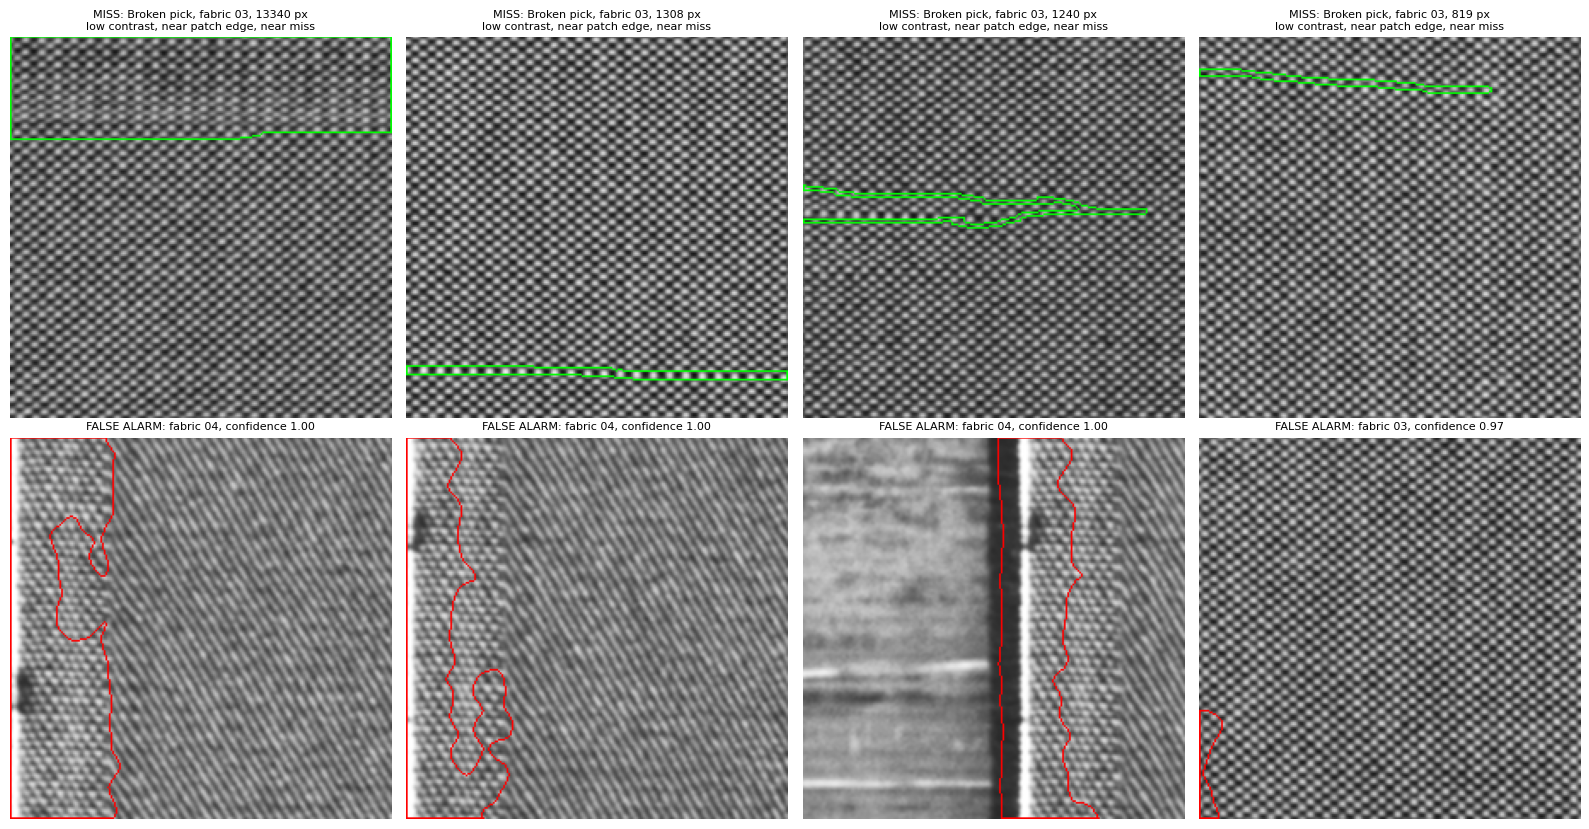

Misses shown: 4 | false alarms shown: 4


In [22]:
def overlay_contours(img, pred, gt):
    rgb = cv2.cvtColor(np.clip(img, 0, 255).astype(np.uint8), cv2.COLOR_GRAY2RGB)
    for m_, col in ((gt, (0, 255, 0)), (pred, (255, 0, 0))):
        cnts, _ = cv2.findContours(m_.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, cnts, -1, col, 1)
    return rgb

frac = LOW_FRAC[FAIL_METHOD]
seen, miss_pick = set(), []
for _, r in miss.sort_values("area", ascending=False).iterrows():
    if r.source not in seen:
        seen.add(r.source); miss_pick.append(r)
    if len(miss_pick) == 4:
        break
fa = patch_df[(patch_df.method == FAIL_METHOD) & (patch_df.group == "normal") & (patch_df.flagged)].sort_values("conf", ascending=False).head(4)

fig, axes = plt.subplots(2, 4, figsize=(16, 8.4))
for ax in axes.ravel():
    ax.axis("off")
for k, r in enumerate(miss_pick):
    it = eval_items[int(r.idx)]; model = get_model(FAIL_METHOD, it["fabric"])
    pred = localize(eval_D[FAIL_METHOD][int(r.idx)], model, frac)[0]
    axes[0, k].imshow(overlay_contours(interior(it["img"]), pred, it["gt"]))
    axes[0, k].set_title(f"MISS: {r["defect_type"]}, fabric {r.fabric}, {int(r.area)} px\n" + ", ".join(r.tags), fontsize=8)
for k, (_, r) in enumerate(fa.iterrows()):
    it = ntest_items[int(r.idx)]; model = get_model(FAIL_METHOD, it["fabric"])
    pred = localize(ntest_D[FAIL_METHOD][int(r.idx)], model, frac)[0]
    axes[1, k].imshow(overlay_contours(interior(it["img"]), pred, np.zeros_like(pred)))
    axes[1, k].set_title(f"FALSE ALARM: fabric {r.fabric}, confidence {r.conf:.2f}", fontsize=8)
plt.tight_layout()
plt.show()
print(f"Misses shown: {len(miss_pick)} | false alarms shown: {len(fa)}")

**FIGURES**  
Heat maps of pixel AUROC and defect detection rate by fabric, detection rate by defect type, and weave-pattern strength against performance.

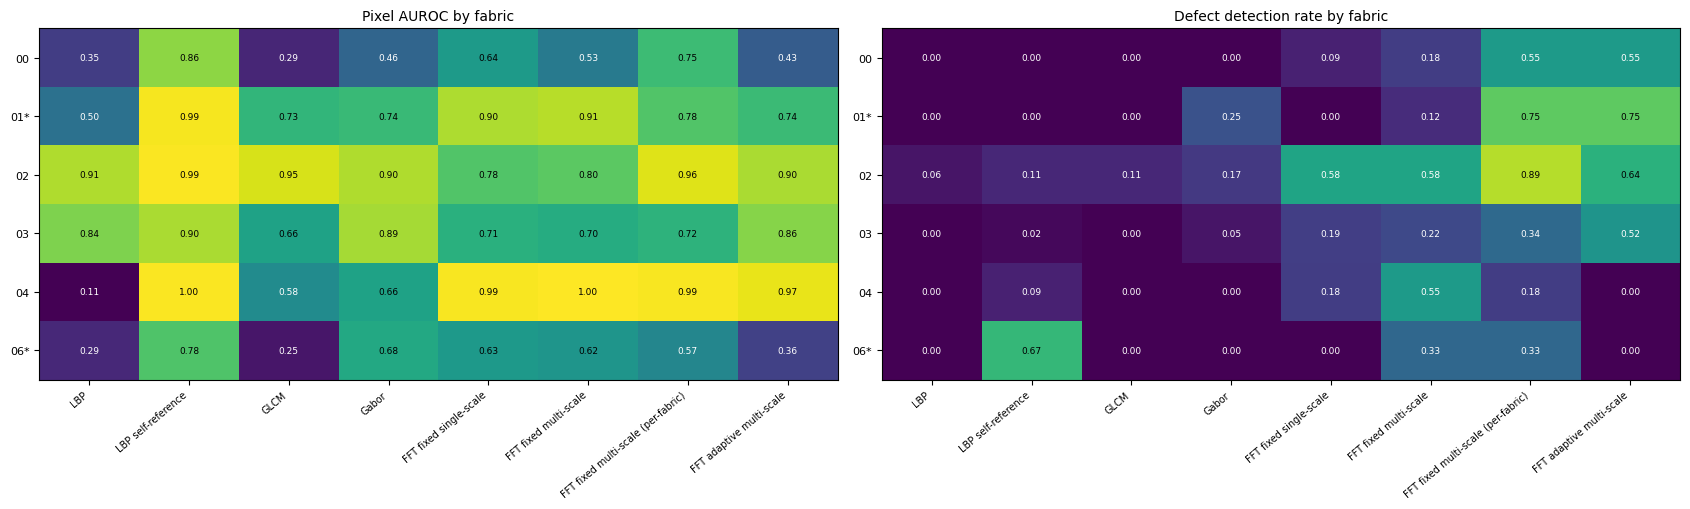

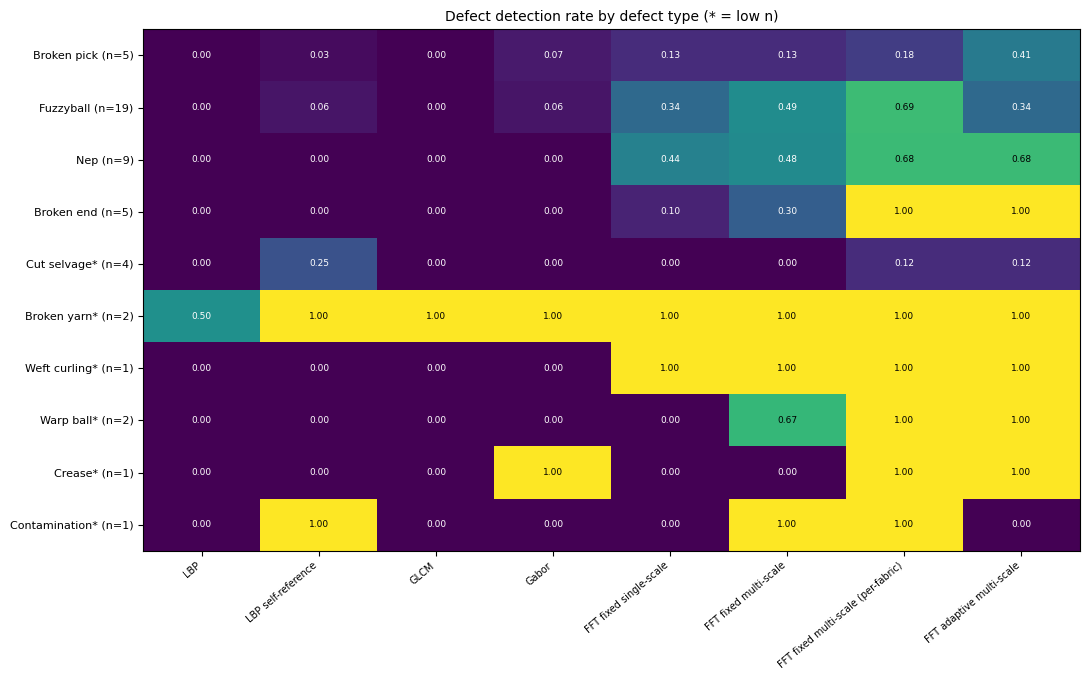

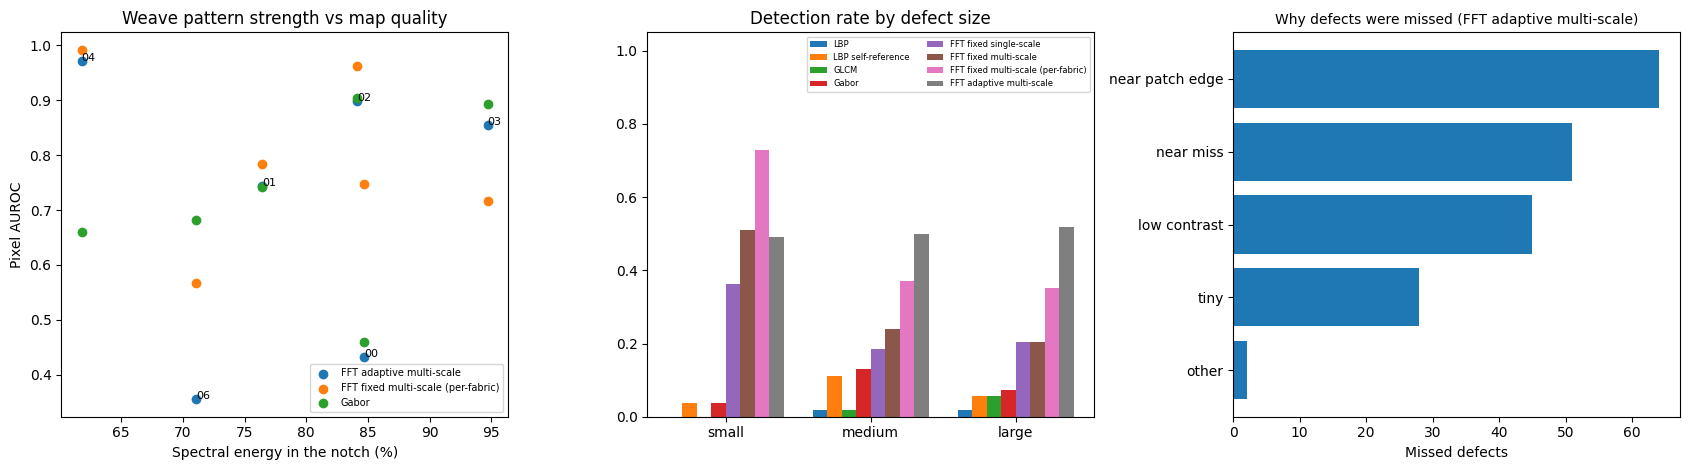

In [23]:
def heat(ax, df, title, row_labels=None, vmin=0, vmax=1):
    im = ax.imshow(df.values.astype(float), cmap="viridis", vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(df.shape[1])); ax.set_xticklabels(df.columns, rotation=40, ha="right", fontsize=7)
    ax.set_yticks(range(df.shape[0])); ax.set_yticklabels(row_labels or list(df.index), fontsize=8)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            v = df.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if v < 0.6 else "black")
    ax.set_title(title, fontsize=10)
    return im

fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))
heat(axes[0], tab_pix_fab, "Pixel AUROC by fabric", [flab(f) for f in fabs], vmin=0.2)
heat(axes[1], tab_det_fab, "Defect detection rate by fabric", [flab(f) for f in fabs])
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 0.45 * len(types) + 2.4))
heat(ax, tab_det_type, "Defect detection rate by defect type (* = low n)", [f"{tlab(t)} (n={int(type_info.loc[t, 'source images'])})" for t in types])
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for m in FOCUS_METHODS:
    axes[0].scatter(fab_feas_df.loc[fabs, "notch_energy_pct"], tab_pix_fab.loc[fabs, m], label=m)
for f in fabs:
    axes[0].annotate(f, (fab_feas_df.loc[f, "notch_energy_pct"], tab_pix_fab.loc[f, FOCUS_METHODS[0]]), fontsize=8)
axes[0].set_xlabel("Spectral energy in the notch (%)"); axes[0].set_ylabel("Pixel AUROC"); axes[0].set_title("Weave pattern strength vs map quality"); axes[0].legend(fontsize=7)
w = 0.8 / len(METHODS)
for i, m in enumerate(METHODS):
    axes[1].bar(np.arange(3) + i * w, tab_det_size[m].values, w, label=m)
axes[1].set_xticks(np.arange(3) + 0.4 - w / 2); axes[1].set_xticklabels(sizes); axes[1].set_ylim(0, 1.05)
axes[1].set_title("Detection rate by defect size"); axes[1].legend(fontsize=6, ncol=2)
if len(tag_counts):
    axes[2].barh(tag_counts.index[::-1], tag_counts.values[::-1])
axes[2].set_title(f"Why defects were missed ({FAIL_METHOD})", fontsize=10); axes[2].set_xlabel("Missed defects")
plt.tight_layout(); plt.show()

**SAVE RESULTS**  
All tables, the interval table, the failure features, per-patch and per-defect records, and the configuration.

In [24]:
tag = EVAL_SPLIT + ("_quick" if QUICK else "")
out = {
    "fabric_counts": counts_fab, "pixel_auroc_by_fabric": tab_pix_fab, "detection_by_fabric": tab_det_fab,
    "covered_by_fabric": tab_cov_fab, "recall_by_fabric": tab_rec_fab, "false_alarm_by_fabric": tab_fpr_fab,
    "image_auroc_by_fabric": tab_iauc_fab, "periodicity": fab_feas_df, "periodicity_correlation": corr_df,
    "type_counts": type_info, "detection_by_type": tab_det_type, "covered_by_type": tab_cov_type,
    "recall_by_type": tab_rec_type, "pixel_auroc_by_type": tab_pix_type,
    "detection_by_size": tab_det_size, "covered_by_size": tab_cov_size, "decomposition": decomp_df,
}
for name, df in out.items():
    df.to_csv(RESULTS_DIR / f"w8_{name}_{tag}.csv")
ci_df.to_csv(RESULTS_DIR / f"w8_bootstrap_intervals_{tag}.csv", index=False)
fd.drop(columns=["tags"], errors="ignore").to_csv(RESULTS_DIR / f"w8_defect_features_{FAIL_METHOD.replace(' ', '_')}_{tag}.csv", index=False)
patch_df.to_csv(RESULTS_DIR / f"w8_patch_results_{tag}.csv", index=False)
defect_eval_df.to_csv(RESULTS_DIR / f"w8_defect_results_{tag}.csv", index=False)
json.dump(dict(cfg=CFG, methods=METHODS, focus=FOCUS_METHODS, eval_split=EVAL_SPLIT, quick=QUICK, seed=SEED, fabrics=FABRICS,
               growth_fraction=LOW_FRAC, size_cuts=[float(x) for x in size_cuts], fail_method=FAIL_METHOD),
          open(RESULTS_DIR / f"w8_config_{tag}.json", "w"), indent=2, default=float)

print("=" * 60)
print("RESULTS SAVED")
print("=" * 60)
print(f"{len(out) + 5} files with prefix w8_ and suffix _{tag} in {RESULTS_DIR}")

RESULTS SAVED
22 files with prefix w8_ and suffix _dev in /content/drive/MyDrive/ECE501/results


**WEEK 8 SUMMARY**  
The main findings, computed from the tables above.

In [25]:
print("=" * 60)
print("WEEK 8 SUMMARY")
print("=" * 60)
print(f"Analysed: {EVAL_SPLIT.upper()} split, {len(eval_items)} defect patches, {len(feat_rows)} true defects, {len(ntest_items)} defect-free patches; TEST split untouched.")
print(f"Fabrics covered: {fabs} (a star marks fabrics with fewer than {CFG['min_sources']} source images)")
print("\nBest method per fabric (pixel AUROC / detection rate):")
print(pd.DataFrame({"pixel AUROC": tab_pix_fab.apply(best_of, axis=1), "detection rate": tab_det_fab.apply(best_of, axis=1)}).to_string())
print("\nHardest fabrics for", ", ".join(FOCUS_METHODS), "(lowest detection rate):")
for m in FOCUS_METHODS:
    s = tab_det_fab[m].sort_values()
    print(f"  {m}: {', '.join(f'{f} ({v:.2f})' for f, v in s.head(2).items())}")
if len(decomp_df):
    print("\nAdaptive gain decomposition (defect detection rate):")
    print(decomp_df[decomp_df.metric == "Defect detection rate"][["effect", "difference", "ci_low", "ci_high"]].round(3).to_string(index=False))
print(f"\nMissed defects ({FAIL_METHOD}): {len(miss)} of {len(fd)}")
if len(tag_counts):
    print("Most common tags among misses:", ", ".join(f"{k} ({v})" for k, v in tag_counts.head(3).items()))
print("\nReading guide: rely on rows without a star; treat intervals that overlap as no clear difference.")

WEEK 8 SUMMARY
Analysed: DEV split, 152 defect patches, 163 true defects, 280 defect-free patches; TEST split untouched.
Fabrics covered: ['00', '01', '02', '03', '04', '06'] (a star marks fabrics with fewer than 5 source images)

Best method per fabric (pixel AUROC / detection rate):
              pixel AUROC                      detection rate
00     LBP self-reference                     tie (2 methods)
01     LBP self-reference                     tie (2 methods)
02     LBP self-reference  FFT fixed multi-scale (per-fabric)
03     LBP self-reference            FFT adaptive multi-scale
04  FFT fixed multi-scale               FFT fixed multi-scale
06     LBP self-reference                  LBP self-reference

Hardest fabrics for FFT adaptive multi-scale, FFT fixed multi-scale (per-fabric), Gabor (lowest detection rate):
  FFT adaptive multi-scale: 06 (0.00), 04 (0.00)
  FFT fixed multi-scale (per-fabric): 04 (0.18), 06 (0.33)
  Gabor: 00 (0.00), 04 (0.00)

Adaptive gain decomposition